# # Experiment 5: Patching Images
1) Patching:  val_f1: 0.3870 , **test_f1: 0.3369**
2) Patching + Aug. :  val_f1 0.3713
3) Patching + NonLinear Class:  val_f1 0.4150 **test_f1: 0.3238**
4) Patching + NonLinear Class + Aug. :  val_f1 0.3693
5) Patching + Fine Tuning: val_f1 0.4128 , **test_f1: 0.3490**
6) Patching +NonLinear Class + Fine Tuning : val_f1 0.4033 , **test_f1: 0.3066**
7) Patching + Aug + Fine Tuning: val_f1 0.3866 **test_f1: 0.3714**
8) Patching + Fine Tuning + AdamW: val_f1 0.4153
9) Patching + Aug(+) + AdamW + Fine Tuning: val_f1 0.3883 **test_f1: 0.3714**
10) Patching + Aug(+) + AdamW + Fine Tuning(backbone.features[-3:]): val_f1 0.4062 **test_f1: 0.3508**
11) Patching + Aug(+) + AdamW + Fine Tuning(backbone.features[-4:]): val_f1 0.4261 **test_f1: 0.3508**
12) Patching + Aug(++) + AdamW + Fine Tuning(backbone.features[-3:]) val_f1 0.3995 **test_f1: 0.3670**
13) Patching + Aug(++) + AdamW + Fine Tuning: val_f1 0.3798 **test_f1: 0.3417**
14) Patching Smart + Aug(+) + AdamW + Fine Tuning: val_f1 0.4675

## ⚙️ **Libraries Import**

In [42]:
# Set seed for reproducibility
SEED = 100

import numpy as np

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
from pathlib import Path


# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
#from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
#!pip install torchview
#from torchview import draw_graph

# Configurazione di TensorBoard e directory
#logs_dir = "tensorboard"
#!pkill -f tensorboard
#%load_ext tensorboard
#!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.6.0+cu124
Device: cuda


## 🔧 **Automatic Configuration**

In [43]:
#(LOCAL vs KAGGLE)

def get_paths():
    """It detects the enviroment and returns the correct path."""
    !ls '/kaggle/input/'
    if os.path.exists('/kaggle/input'):
        print("🌍 Detetected enviroment: KAGGLE")
        input_dir = Path('/kaggle/input/patching-spotdel/')
        output_dir = Path('/kaggle/working/')
    else:
        print("💻 Detetected enviroment: LOCAL")
        # Impostate la vostra cartella di input e output locali
        input_dir = Path('../data/archive/')
        output_dir = Path('../data/output/')

        # Crea le cartelle se non esistono in locale
        output_dir.mkdir(parents=True, exist_ok=True)

    return input_dir, output_dir

INPUT_DIR, OUTPUT_DIR = get_paths()
print(f"Input directory: {INPUT_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
!ls '/kaggle/input/patching-dataset/'


patching-spotdel
🌍 Detetected enviroment: KAGGLE
Input directory: /kaggle/input/patching-spotdel
Output directory: /kaggle/working
ls: cannot access '/kaggle/input/patching-dataset/': No such file or directory


In [44]:
#creo cartella per i models
models_dir=OUTPUT_DIR/'models'
models_dir.mkdir(parents=True, exist_ok=True)

## **Constants**

In [45]:
#tutte le costanti utili in un unico posto :)

BATCH_SIZE = 256

# ImageNet normalization statistics
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)


## ⏳ **Data Loading**

In [46]:
PATCHES_DIR = INPUT_DIR  

# --- Load Training Patches ---
# Load images 
train_images = np.load(PATCHES_DIR / 'train_patches_images.npy').astype('float32')
train_groups = np.load(PATCHES_DIR / 'train_patches_groups.npy')

train_labels_array = np.load(PATCHES_DIR / 'train_patches_labels.npy')
train_labels = pd.DataFrame(train_labels_array, columns=['label'])
# --- OPTIONAL: Map integers back to class names ---
# If your npy file has integers (0-3) and you want the string names in the CSV:
label_mapping_inv = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}
train_labels['label'] = train_labels['label'].map(label_mapping_inv)
#df.to_csv('train_patches_labels.csv', index=False)
#print(train_labels.head())

# Optional: Load masks if you need them (though MobileNet classification usually doesn't)
# train_masks = np.load(PATCHES_DIR / 'train_patches_masks.npy').astype('float32')

print("Data loaded sucessfully!")
print(f"Train images shape: {train_images.shape}")
print(f"Train labels shape: {train_labels.shape}")
print(f"Train groups shape: {train_groups.shape}")

Data loaded sucessfully!
Train images shape: (5640, 224, 224, 3)
Train labels shape: (5640, 1)
Train groups shape: (5640,)


## 🔎 **Data Analysis**

In [47]:
#LABELS ANALYSIS AND DISTRIBUTION
print(train_labels.describe())

print("\n--- Unique Labels ---")
unique_labels = train_labels['label'].unique()
print(unique_labels)

print("\n--- Label Distribution ---")
label_counts = train_labels['label'].value_counts()
label_percentages = train_labels['label'].value_counts(normalize=True) * 100
label_stats = pd.DataFrame({
    'count': label_counts,
    'percentage': label_percentages
})
print(label_stats.round(2))

            label
count        5640
unique          4
top     Luminal B
freq         1979

--- Unique Labels ---
['Triple negative' 'Luminal B' 'Luminal A' 'HER2(+)']

--- Label Distribution ---
                 count  percentage
label                             
Luminal B         1979       35.09
HER2(+)           1551       27.50
Luminal A         1522       26.99
Triple negative    588       10.43


In [48]:
#number of classes
NUM_CLASSES = len(unique_labels)

## 🔄 **Data Processing**

In [49]:
# Target preparation

# Define the mapping between textual labels and numerical value (enum)
label_mapping = {
    'Luminal A': 0,
    'Luminal B': 1,
    'HER2(+)': 2,
    'Triple negative': 3
}

# Add new column 'target' to train_labels dataframe
train_labels['target'] = train_labels['label'].map(label_mapping)

target = np.array(train_labels['target']).astype('float32')

In [50]:
# --- Calculate Class Weights (Important for Patches) ---
# Patch distribution might differ from original image distribution

# weight = (num_total_training / (num_classes * num_for_class))
# Reindex label_stats to follow the explicit mapping order instead of alphabetical order
ordered_labels = [label for label, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
label_stats_ordered = label_stats.reindex(ordered_labels)
class_weights = (len(train_labels) / (NUM_CLASSES * label_stats_ordered['count'])).astype(np.float32)

# Create list useful later for tensor transformation
class_weights_list = list(class_weights)
print(f"Balanced WEIGHT for each class:\t{class_weights_list}")
print(f"Class order: {ordered_labels}")
class_weights_tensor = torch.tensor(class_weights_list, dtype=torch.float32).to(device)


Balanced WEIGHT for each class:	[0.9264126420021057, 0.7124810218811035, 0.9090909361839294, 2.3979592323303223]
Class order: ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']


In [51]:
from sklearn.model_selection import GroupShuffleSplit
# --- 3. Group-Aware Split (Train/Val) ---
# We must use groups to prevent leakage (patches from same image must stay together)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(gss.split(train_images, train_labels, groups=train_groups))

X_train, X_val = train_images[train_idx], train_images[val_idx]
y_train, y_val = target[train_idx], target[val_idx]
# If you used masks:
# train_masks, val_masks = train_masks[train_idx], train_masks[val_idx]

# Print the shapes of the resulting datasets
print("\n--- Split Results ---")
print("Training Data Shape:", X_train.shape)
print("Training Label Shape:", y_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Validation Label Shape:", y_val.shape)


--- Split Results ---
Training Data Shape: (4506, 224, 224, 3)
Training Label Shape: (4506,)
Validation Data Shape: (1134, 224, 224, 3)
Validation Label Shape: (1134,)


In [52]:
# Define the input shape based on the training data
INPUT_SHAPE = (X_train.shape[3], X_train.shape[1], X_train.shape[2])
print(INPUT_SHAPE)

(3, 224, 224)


In [53]:
class MyDataset(torch.utils.data.Dataset):
    """Custom PyTorch Dataset with optional augmentation and normalization."""

    def __init__(self, data, labels, augmentation=None, normalize_imagenet=False):
        """
        Args:
            data: numpy array of images (N, C, H, W) in range [0, 1]
            labels: numpy array of labels
            augmentation: transforms for data augmentation
            normalize_imagenet: whether to apply ImageNet normalization
        """
        self.data = torch.from_numpy(data).permute(0, 3, 1, 2)
        self.labels = torch.from_numpy(labels).squeeze().long()
        self.augmentation = augmentation
        self.normalize_imagenet = normalize_imagenet

        # ImageNet normalization transform
        if normalize_imagenet:
            self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
        else:
            self.normalize = None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx].clone()  # Clone to avoid modifying original
        label = self.labels[idx]

        # Apply augmentation if provided (on images in [0, 1] range)
        if self.augmentation:
            image = self.augmentation(image)

        # Apply ImageNet normalization if requested
        if self.normalize:
            image = self.normalize(image)

        return image, label

In [54]:
train_transforms = transforms.Compose([ 
    transforms.RandomHorizontalFlip(p=0.1),
    #transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    #transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(90),
    #transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),
])

# Convert numpy arrays to customized PyTorch datasets (pairs features with labels)
train_ds = MyDataset(X_train, y_train, augmentation=train_transforms, normalize_imagenet=True)
val_ds   = MyDataset(X_val, y_val, augmentation=None, normalize_imagenet=True)

In [55]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [56]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [57]:
# print batch shape
for xb, yb in train_loader:
    print("Features batch shape:", xb.shape)
    print("Labels batch shape:", yb.shape)
    break # Stop after getting one batch

Features batch shape: torch.Size([256, 3, 224, 224])
Labels batch shape: torch.Size([256])


## 🧮 **Network Parameters**

In [ ]:
# Training parameters
LEARNING_RATE = 0.001
EPOCHS = 200
PATIENCE = 20

# Regularisation
DROPOUT_RATE = 0.4      # Dropout probability
L1_LAMBDA = 0.001           # L1 penalty 
L2_LAMBDA = 0.01            # L2 penalty 
LABEL_SMOOTHING = 0.05      # Penalises over-confident logits

# Set up loss function
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    label_smoothing=LABEL_SMOOTHING
)


##  🧠 **Training Functions**

In [59]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device):
    """Train for one epoch."""
    model.train()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def validate_one_epoch(model, val_loader, criterion, device):
    """Validate for one epoch."""
    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='macro'
    )

    return epoch_loss, epoch_f1


def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, verbose=1, experiment_name="",
        scheduler=None, snapshot_interval=None):
    """Train the neural network model with optional snapshot ensembling support."""

    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    for epoch in range(1, epochs + 1):
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device
        )

        if scheduler is not None:
            scheduler.step()

        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        if verbose > 0:
            lr_curr = optimizer.param_groups[0]['lr']
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | LR: {lr_curr:.6f} | "
                    f"Train: Loss={train_loss:.4f}, F1={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1={val_f1:.4f}")

        # Save snapshots at the end of each cycle
        if snapshot_interval and epoch % snapshot_interval == 0:
            snap_name = f"{experiment_name}_snapshot_ep{epoch}.pt"
            torch.save(model.state_dict(), OUTPUT_DIR/'models'/snap_name)
            print(f"📸 Snapshot saved: {snap_name}")
            optimizer = torch.optim.AdamW(tl_model.parameters(), lr=LR_MAX, weight_decay=L2_LAMBDA)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
                optimizer,
                T_0=CYCLE_LEN,
                T_mult=1,
                eta_min=1e-6
            )

        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load(OUTPUT_DIR/'models'/(experiment_name+'_model.pt')))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    if patience == 0:
        torch.save(model.state_dict(), OUTPUT_DIR/'models'/(experiment_name+'_model.pt'))

    return model, training_history

## 🛠️ **Transfer Learning**

In [60]:
class ModelTransferLearning(nn.Module):
    """
    CNN model with pretrained weights for transfer learning.

    IMPORTANT: This model expects ImageNet-normalized inputs!
    Images should be normalized with mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]
    """
    def __init__(self, num_classes, dropout_rate=0.3, freeze_backbone=True):
        super().__init__()

        # Load weights pretrained on ImageNet
        self.backbone = torchvision.models.efficientnet_b0(
            weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT
        )

        # Freeze the backbone layers (features)
        if freeze_backbone:
            for param in self.backbone.features.parameters():
                param.requires_grad = False

        # Replace classifier (Always trainable)
        num_features = self.backbone.classifier[-1].in_features
        hidden_dim = 256
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate),
            nn.Linear(num_features, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

In [61]:
# Choose your model 
MODEL_NAME = "mobilenet_v3_small"

# Create transfer learning model
tl_model = ModelTransferLearning(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)

# Display model summary
summary(tl_model, input_size=INPUT_SHAPE)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 112, 112]             864
       BatchNorm2d-2         [-1, 32, 112, 112]              64
              SiLU-3         [-1, 32, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]             288
       BatchNorm2d-5         [-1, 32, 112, 112]              64
              SiLU-6         [-1, 32, 112, 112]               0
 AdaptiveAvgPool2d-7             [-1, 32, 1, 1]               0
            Conv2d-8              [-1, 8, 1, 1]             264
              SiLU-9              [-1, 8, 1, 1]               0
           Conv2d-10             [-1, 32, 1, 1]             288
          Sigmoid-11             [-1, 32, 1, 1]               0
SqueezeExcitation-12         [-1, 32, 112, 112]               0
           Conv2d-13         [-1, 16, 112, 112]             512
      BatchNorm2d-14         [-1, 16, 1

In [62]:
# Setup training
EXPERIMENT_NAME = f"patching_{MODEL_NAME}"

optimizer = torch.optim.AdamW(tl_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)
#optimizer = torch.optim.Adam(tl_model.parameters(), lr=LEARNING_RATE)
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

## 🧩 Cross-Validation Ensemble
Allenamento su più fold (GroupKFold sui gruppi immagine) per ridurre overfitting e mediare modelli.

In [ ]:
# Allenamento K-fold con due fasi (warmup + fine-tuning breve) per ridurre overfitting
from sklearn.model_selection import GroupKFold

FOLDS = 3
WARMUP_EPOCHS = 5         # breve warmup solo classifier
FINETUNE_EPOCHS = 8       # fine-tuning breve
UNFREEZE_BLOCKS = 1       # quanti blocchi EfficientNet sbloccare
WARMUP_LR = LEARNING_RATE
FINETUNE_LR = 5e-4

gkf = GroupKFold(n_splits=FOLDS)

fold_histories = []
fold_model_paths = []

for fold, (tr_idx, val_idx) in enumerate(gkf.split(train_images, target, groups=train_groups), start=1):
    print(f"\n🧩 Fold {fold}/{FOLDS}")
    X_tr, X_val = train_images[tr_idx], train_images[val_idx]
    y_tr, y_val = target[tr_idx], target[val_idx]

    train_ds_cv = MyDataset(X_tr, y_tr, augmentation=train_transforms, normalize_imagenet=True)
    val_ds_cv = MyDataset(X_val, y_val, augmentation=None, normalize_imagenet=True)

    train_loader_cv = make_loader(train_ds_cv, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
    val_loader_cv = make_loader(val_ds_cv, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

    # --- Warmup: backbone frozen, solo classifier ---
    model_cv = ModelTransferLearning(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)
    optimizer_warmup = torch.optim.AdamW(model_cv.parameters(), lr=WARMUP_LR, weight_decay=L2_LAMBDA)
    scaler_cv = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

    exp_name_fold = f"{EXPERIMENT_NAME}_fold{fold}"
    model_cv, history_warmup = fit(
        model=model_cv,
        train_loader=train_loader_cv,
        val_loader=val_loader_cv,
        epochs=WARMUP_EPOCHS,
        criterion=criterion,
        optimizer=optimizer_warmup,
        scaler=scaler_cv,
        device=device,
        verbose=1,
        experiment_name=exp_name_fold,
        patience=min(PATIENCE, 3)
    )

    # --- Fine-tuning: sblocca ultimi blocchi + classifier ---
    for p in model_cv.parameters():
        p.requires_grad = False
    for p in model_cv.backbone.classifier.parameters():
        p.requires_grad = True
    for block in model_cv.backbone.features[-UNFREEZE_BLOCKS:]:
        for p in block.parameters():
            p.requires_grad = True

    optimizer_ft = torch.optim.AdamW(filter(lambda p: p.requires_grad, model_cv.parameters()), lr=FINETUNE_LR, weight_decay=L2_LAMBDA)

    model_cv, history_ft = fit(
        model=model_cv,
        train_loader=train_loader_cv,
        val_loader=val_loader_cv,
        epochs=FINETUNE_EPOCHS,
        criterion=criterion,
        optimizer=optimizer_ft,
        scaler=scaler_cv,
        device=device,
        verbose=1,
        experiment_name=exp_name_fold,
        patience=min(PATIENCE, 3)
    )

    # Combina storici warmup+finetune per tracciarli insieme
    history_combined = {
        'train_loss': history_warmup['train_loss'] + history_ft['train_loss'],
        'val_loss': history_warmup['val_loss'] + history_ft['val_loss'],
        'train_f1': history_warmup['train_f1'] + history_ft['train_f1'],
        'val_f1': history_warmup['val_f1'] + history_ft['val_f1'],
    }

    fold_histories.append(history_combined)
    fold_model_path = OUTPUT_DIR/'models'/(exp_name_fold + '_model.pt')
    fold_model_paths.append(fold_model_path)
    print(f"✅ Saved fold model to {fold_model_path}")


In [63]:
%%time

# Train with transfer learning
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=15,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=1,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
)

final_val_f1 = round(max(tl_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')


Training 15 epochs...
Epoch   1/15 | LR: 0.001000 | Train: Loss=1.3788, F1=0.2805 | Val: Loss=1.3226, F1=0.3389
Epoch   2/15 | LR: 0.001000 | Train: Loss=1.3147, F1=0.3557 | Val: Loss=1.3232, F1=0.3872
Epoch   3/15 | LR: 0.001000 | Train: Loss=1.2732, F1=0.3893 | Val: Loss=1.2966, F1=0.4012
Epoch   4/15 | LR: 0.001000 | Train: Loss=1.2575, F1=0.4058 | Val: Loss=1.3127, F1=0.4013
Epoch   5/15 | LR: 0.001000 | Train: Loss=1.2472, F1=0.4056 | Val: Loss=1.3072, F1=0.3986
Epoch   6/15 | LR: 0.001000 | Train: Loss=1.2395, F1=0.4205 | Val: Loss=1.2873, F1=0.4176
Epoch   7/15 | LR: 0.001000 | Train: Loss=1.2239, F1=0.4207 | Val: Loss=1.3078, F1=0.4019
Epoch   8/15 | LR: 0.001000 | Train: Loss=1.2151, F1=0.4250 | Val: Loss=1.2813, F1=0.4046
Epoch   9/15 | LR: 0.001000 | Train: Loss=1.2007, F1=0.4414 | Val: Loss=1.3066, F1=0.4067
Epoch  10/15 | LR: 0.001000 | Train: Loss=1.1963, F1=0.4466 | Val: Loss=1.3043, F1=0.3798
Epoch  11/15 | LR: 0.001000 | Train: Loss=1.1949, F1=0.4375 | Val: Loss=1.2944

In [64]:
# Load the transfer learning model
# Start from the previously trained weights
tl_model = ModelTransferLearning(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)
tl_model.load_state_dict(torch.load(OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")))

# Strategy: Freeze everything first, then unfreeze the last few blocks
for param in tl_model.parameters():
    param.requires_grad = False

# The classifier is always trainable
for param in tl_model.backbone.classifier.parameters():
    param.requires_grad = True

# Unfreeze the last 2 blocks of the feature extractor (EfficientNet-B0 has 9 blocks usually)
for block in tl_model.backbone.features[-1:]:
    for param in block.parameters():
        param.requires_grad = True

# Check trainable parameters
trainable_params = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in tl_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")

# Snapshot ensemble schedule
CYCLE_LEN = 10   # epochs per cosine cycle
N_CYCLES = 5     # number of snapshots to keep (one per cycle)
TOTAL_EPOCHS = CYCLE_LEN * N_CYCLES
LR_MAX = 0.01

optimizer = torch.optim.AdamW(tl_model.parameters(), lr=LR_MAX, weight_decay=L2_LAMBDA)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=CYCLE_LEN,
    T_mult=1,
    eta_min=1e-6
)

# Train with snapshot ensembling (no early stopping to complete all cycles)
tl_model, tl_history = fit(
    model=tl_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=TOTAL_EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=1,
    experiment_name=EXPERIMENT_NAME,
    patience=0,
    scheduler=scheduler,
    snapshot_interval=CYCLE_LEN
)

final_val_f1 = round(max(tl_history['val_f1']) * 100, 2)
print(f'Final validation F1: {final_val_f1}%')

Trainable parameters: 417,284 / 4,012,672
Training 50 epochs...
Epoch   1/50 | LR: 0.009755 | Train: Loss=1.3592, F1=0.3845 | Val: Loss=1.7034, F1=0.3734
Epoch   2/50 | LR: 0.009045 | Train: Loss=1.1955, F1=0.4588 | Val: Loss=1.4000, F1=0.3823
Epoch   3/50 | LR: 0.007939 | Train: Loss=1.0662, F1=0.5118 | Val: Loss=1.4267, F1=0.4133
Epoch   4/50 | LR: 0.006545 | Train: Loss=0.9947, F1=0.5626 | Val: Loss=1.6444, F1=0.4162
Epoch   5/50 | LR: 0.005001 | Train: Loss=0.9322, F1=0.5842 | Val: Loss=1.4354, F1=0.4093
Epoch   6/50 | LR: 0.003456 | Train: Loss=0.8635, F1=0.6211 | Val: Loss=1.4745, F1=0.4275
Epoch   7/50 | LR: 0.002062 | Train: Loss=0.8286, F1=0.6399 | Val: Loss=1.5066, F1=0.4266
Epoch   8/50 | LR: 0.000956 | Train: Loss=0.7893, F1=0.6549 | Val: Loss=1.4770, F1=0.4454
Epoch   9/50 | LR: 0.000246 | Train: Loss=0.7489, F1=0.6809 | Val: Loss=1.4852, F1=0.4414
Epoch  10/50 | LR: 0.010000 | Train: Loss=0.7604, F1=0.6774 | Val: Loss=1.4851, F1=0.4386
📸 Snapshot saved: patching_mobilenet

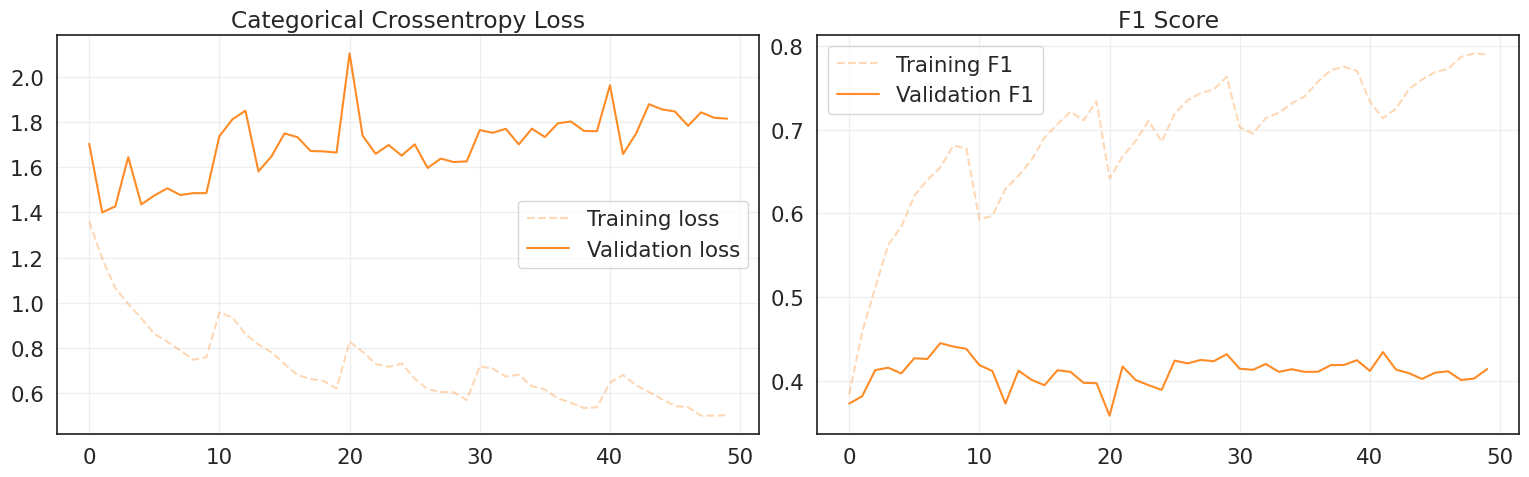

In [65]:
# @title Plot History
# Create a figure with two side-by-side subplots
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(tl_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(tl_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Categorical Crossentropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation Accuracy on the second axis
ax2.plot(tl_history['train_f1'], label='Training F1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(tl_history['val_f1'], label='Validation F1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.4189
Precision over the validation set: 0.4197
Recall over the validation set: 0.4189
F1 score over the validation set: 0.4168
-----------------------------------
CLASS                ACCURACY
-----------------------------------
Luminal A            50.18%
Luminal B            44.14%
HER2(+)              35.74%
Triple negative      34.36%
-----------------------------------


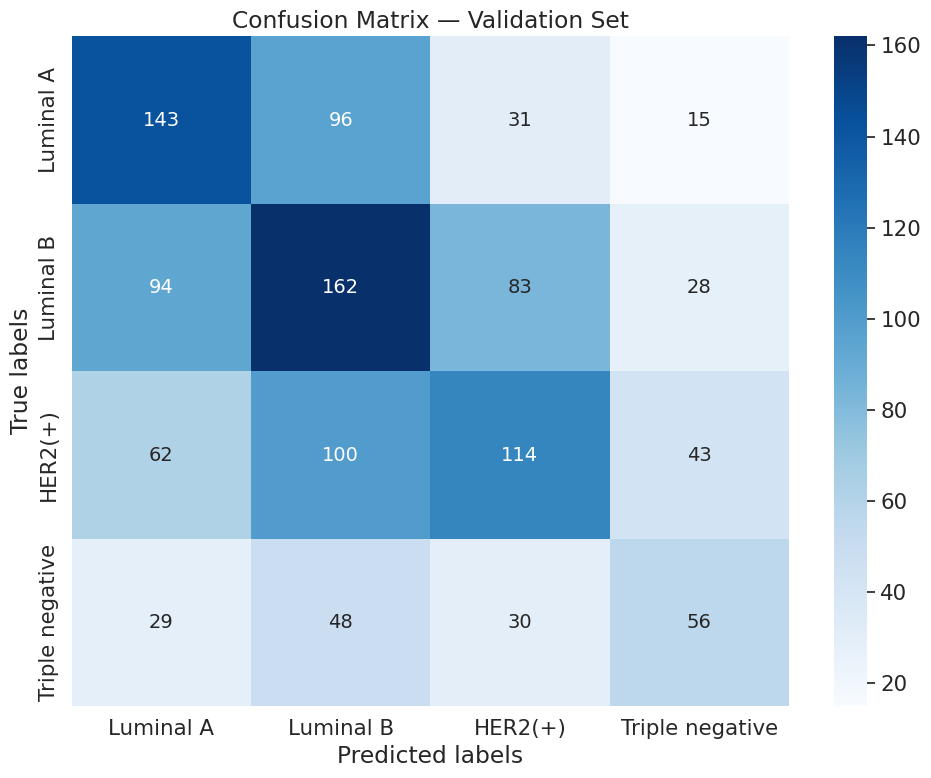

In [66]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
class_labels = ['Luminal A', 'Luminal B', 'HER2(+)', 'Triple negative']

val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = tl_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Store accuracy per class with desired names
#Calcola il totale per ogni classe reale (somma delle righe)
true_totals = cm.sum(axis=1)
#Normalizza la matrice (gestendo la divisione per zero)
cm_perc = np.divide(cm.astype(float), true_totals[:, None], out=np.zeros_like(cm, dtype=float), where=true_totals[:, None]>0)
#Estrai la diagonale (che è l'accuratezza per ogni classe)
per_class_accuracy = cm_perc.diagonal()

accuracy_LA = per_class_accuracy[0]
accuracy_LB = per_class_accuracy[1]
accuracy_H2 = per_class_accuracy[2]
accuracy_TN = per_class_accuracy[3]

print("-" * 35)
print(f"{'CLASS':<20} {'ACCURACY'}")
print("-" * 35)

print(f"{'Luminal A':<20} {accuracy_LA:.2%}")
print(f"{'Luminal B':<20} {accuracy_LB:.2%}")
print(f"{'HER2(+)':<20} {accuracy_H2:.2%}")
print(f"{'Triple negative':<20} {accuracy_TN:.2%}")
print("-" * 35)

# Visualise confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues',
            xticklabels=class_labels,
            yticklabels=class_labels
            )
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

## 🕹️ **Test Inference**

In [67]:
#PREPARE DATA FOR TESTING
# Load images 
test_images = np.load(PATCHES_DIR / 'test_patches_images.npy').astype('float32')
test_groups = np.load(PATCHES_DIR / 'test_patches_groups.npy')

test_ds = MyDataset(test_images, np.zeros(len(test_images)), augmentation=None, normalize_imagenet=True)
test_loader = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

In [ ]:
import glob

# Locate snapshots and fold models
snapshot_files = sorted(list((OUTPUT_DIR/"models").glob(f"{EXPERIMENT_NAME}_snapshot_ep*.pt")))
fold_files = sorted(list((OUTPUT_DIR/"models").glob(f"{EXPERIMENT_NAME}_fold*_model.pt")))

# Combine (preserve order, drop duplicates)
ensemble_files = list(dict.fromkeys(snapshot_files + fold_files))

# Fallback to single model if nothing else is available
if len(ensemble_files) == 0:
    print("⚠️ Nessun modello di ensemble trovato, uso il modello singolo.")
    ensemble_files = [OUTPUT_DIR/"models"/(EXPERIMENT_NAME+"_model.pt")]

print(f"👥 Found {len(ensemble_files)} models for ensemble: {[p.name for p in ensemble_files]}")

👥 Found 5 models for ensemble: ['patching_mobilenet_v3_small_snapshot_ep10.pt', 'patching_mobilenet_v3_small_snapshot_ep20.pt', 'patching_mobilenet_v3_small_snapshot_ep30.pt', 'patching_mobilenet_v3_small_snapshot_ep40.pt', 'patching_mobilenet_v3_small_snapshot_ep50.pt']


In [ ]:
all_models_probs = []

for idx, model_path in enumerate(ensemble_files):
    print(f"🤖 Inference with model {idx+1}/{len(ensemble_files)}: {model_path.name}...")

    current_model = ModelTransferLearning(NUM_CLASSES, DROPOUT_RATE, freeze_backbone=True).to(device)
    current_model.load_state_dict(torch.load(model_path))
    current_model.eval()

    model_probs = []
    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(device)
            logits = current_model(xb)
            probs = torch.nn.functional.softmax(logits, dim=1)
            model_probs.append(probs.cpu().numpy())

    all_models_probs.append(np.concatenate(model_probs))

    # Clear memory before next model
    del current_model
    torch.cuda.empty_cache()

print("📊 Averaging predictions across models...")
flat_probs = np.mean(np.array(all_models_probs), axis=0)

# --- 4. Aggregate Predictions by Group (Image) ---
print("Aggregating predictions by image group...")


df_patches = pd.DataFrame({
    'group_id': test_groups,
    'prob_0': flat_probs[:, 0],
    'prob_1': flat_probs[:, 1],
    'prob_2': flat_probs[:, 2],
    'prob_3': flat_probs[:, 3]
})


df_images = df_patches.groupby('group_id').mean().reset_index()
prob_cols = ['prob_0', 'prob_1', 'prob_2', 'prob_3']
df_images['final_pred'] = df_images[prob_cols].idxmax(axis=1).str.replace('prob_', '').astype(int)

print(f"Total original images inferred: {len(df_images)}")
print(df_images.head())


🤖 Inference with model 1/5: patching_mobilenet_v3_small_snapshot_ep10.pt...
🤖 Inference with model 2/5: patching_mobilenet_v3_small_snapshot_ep20.pt...
🤖 Inference with model 3/5: patching_mobilenet_v3_small_snapshot_ep30.pt...
🤖 Inference with model 4/5: patching_mobilenet_v3_small_snapshot_ep40.pt...
🤖 Inference with model 5/5: patching_mobilenet_v3_small_snapshot_ep50.pt...
📊 Averaging predictions across models...
Aggregating predictions by image group...
Total original images inferred: 477
       group_id    prob_0    prob_1    prob_2    prob_3  final_pred
0  img_0000.png  0.302703  0.445143  0.142423  0.109731           1
1  img_0001.png  0.082847  0.435995  0.244744  0.236415           1
2  img_0002.png  0.046674  0.924627  0.004005  0.024695           1
3  img_0003.png  0.256579  0.214649  0.328458  0.200314           2
4  img_0004.png  0.438524  0.238038  0.266077  0.057362           0


In [70]:
# --- 5. Format Submission ---
target_to_label = {
    0: 'Luminal A',
    1: 'Luminal B',
    2: 'HER2(+)',
    3: 'Triple negative'
}

# Map the numeric prediction to the string label
df_images['label_string'] = df_images['final_pred'].map(target_to_label)

# CORRECTION: group_id already contains the filename (e.g., 'img_0000.png')
# so we just copy it to 'sample_index' without formatting.
df_images['sample_index'] = df_images['group_id']

# Select only required columns
submission = df_images[['sample_index', 'label_string']].rename(columns={'label_string': 'label'})

# Save
csv_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(csv_path, index=False)

print(f"✅ Submission saved to: {csv_path}")
print(submission.head())

✅ Submission saved to: /kaggle/working/submission.csv
   sample_index      label
0  img_0000.png  Luminal B
1  img_0001.png  Luminal B
2  img_0002.png  Luminal B
3  img_0003.png    HER2(+)
4  img_0004.png  Luminal A
